In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('EVMon.csv')

In [5]:
df.head()

,year,month,units,cumulative_units
0,2012,Jan,1317,1317
1,2012,Feb,1566,2883
2,2012,Mar,3815,6698
3,2012,Apr,3565,10263
4,2012,May,3361,13624


In [3]:
df.columns

Index(['year', 'month', 'units'], dtype='object')

In [8]:
import statsmodels.api as sm


df['cumulative_units'] = df['units'].cumsum()

X = df[['cumulative_units']].copy()
X['cumulative_units_squared'] = X['cumulative_units'] ** 2
X = sm.add_constant(X)  # Adds a constant term to the predictor
y = df['units']

model = sm.OLS(y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                  units   R-squared:                       0.890
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                     261.9
Date:                Wed, 28 May 2025   Prob (F-statistic):           7.83e-32
Time:                        23:44:22   Log-Likelihood:                -723.19
No. Observations:                  68   AIC:                             1452.
Df Residuals:                      65   BIC:                             1459.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

## Convert the regression results to N, p, q values for the Bass model

In [9]:
a = model.params['const']
b = model.params['cumulative_units']
c = model.params['cumulative_units_squared']

print(f"a (constant): {a}")
print(f"b (cumulative_units): {b}")
print(f"c (cumulative_units_squared): {c}")

a (constant): 4974.028724606009
b (cumulative_units): 0.05766393233888163
c (cumulative_units_squared): -8.917109858495491e-09


In [11]:
from math import sqrt

N = (-b - sqrt(b ** 2 - 4 * a * c)) / (2 * c)
p = a/N
q = b-p

print(f"N (Total market size): {N}")
print(f"p (coefficient of innovation): {p}")  
print(f"q (coefficient of q): {q}")


N (Total market size): 6551799.671802049
p (coefficient of innovation): 0.0007591851054319431
q (coefficient of q): 0.05690474723344969


## Step 3: Forecast using the Bass model results

In [12]:
# Predicting future values

def bass_model(p, q, N, init_case, T):

    """
    init_case refers to the initial number of adopters at time t=0
    T refers to the number of time periods for which we want to predict future sales
    """
    S = np.zeros(T)
    Y = np.zeros(T + 1)
    Y[0] = init_case
    for t in range(T):
        S[t] = p * N + (q - p) * Y[t] - (q / N) * (Y[t] ** 2)
        Y[t + 1] = Y[t] + S[t]
    return S

# Example usage (replace p, q, N, n0, NTS with actual values)


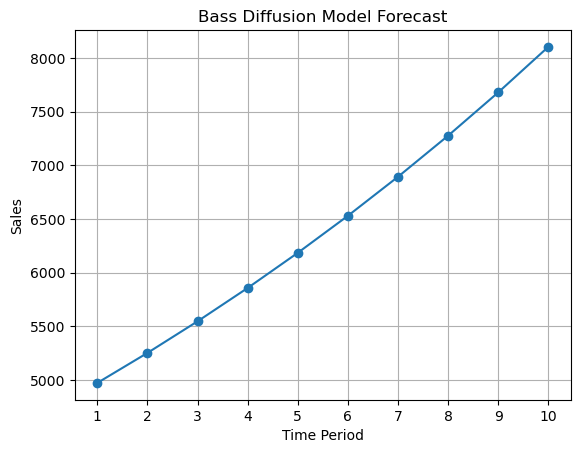

In [13]:
bass_model(p, q, N, init_case=0, T=10)
import matplotlib.pyplot as plt
S = bass_model(p, q, N, init_case=0, T=10)
plt.plot(range(1, 11), S, marker='o')
plt.title('Bass Diffusion Model Forecast')
plt.xlabel('Time Period')
plt.ylabel('Sales')
plt.xticks(range(1, 11))
plt.grid()
plt.show()